In [1]:
import os

from bedrock_agentcore.memory import MemoryClient
from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from langchain.tools import tool
from langgraph_checkpoint_aws import AgentCoreMemorySaver
from langchain_google_genai import ChatGoogleGenerativeAI

load_dotenv()  # reads GEMINI_API_KEY from a .env file, if present

GEMINI_MODEL = os.getenv("GEMINI_MODEL", "gemini-3.8-flash")
# AgentCore Memory lives in an AWS Region
REGION = os.getenv("AWS_REGION", os.getenv("AWS_DEFAULT_REGION", "us-east-1"))
print(f"Model: {GEMINI_MODEL} | Region: {REGION}")

Model: gemini-3.8-flash | Region: us-east-1


In [2]:
client = MemoryClient(region_name=REGION)
memory = client.create_or_get_memory(
    name="MathLanggraphAgentGroq",
    description="Short-term memory for the LangGraph math agent",
)
memory_id = memory["id"]
print("Memory ID:", memory_id, "| status:", memory.get("status"))

Memory ID: MathLanggraphAgentGroq-MfOvjL6j4T | status: ACTIVE


In [4]:
checkpointer = AgentCoreMemorySaver(memory_id, region_name=REGION)
llm = ChatGoogleGenerativeAI(model=GEMINI_MODEL, vertexai=True)

In [5]:
@tool
def add(a: int, b: int) -> int:
    """Add two integers and return the result."""
    return a + b


@tool
def multiply(a: int, b: int) -> int:
    """Multiply two integers and return the result."""
    return a * b


tools = [add, multiply]

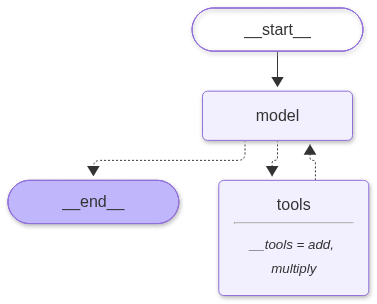

In [6]:
graph = create_agent(
    model=llm,
    tools=tools,
    system_prompt="You are a helpful assistant. Use the tools for every calculation.",
    checkpointer=checkpointer,
)
graph

In [12]:
config = {
    "configurable": {
        "thread_id": "session-1",  # REQUIRED: maps to AgentCore session_id
        "actor_id": "react-agent-1",  # REQUIRED: maps to AgentCore actor_id
    }
}

inputs = {"messages": [{"role": "user", "content": "What is 1337 times 515321? Then add 412 and return the value to me."}]}

for chunk in graph.stream(inputs, stream_mode="updates", config=config):
    print(chunk)

{'model': {'messages': [AIMessage(content=[], additional_kwargs={'function_call': {'name': 'multiply', 'arguments': '{"b": 515321, "a": 1337}'}, '__gemini_function_call_thought_signatures__': {'call_9315475463761678280': 'AY89a19KoRuUl5coKbhVHOFKiNNiM5MJ9dIbhSX2kmXXjcPvo0Y2LuSsiy3/QW3xbBKlopPTIjj98IEv4L9RFeGPcE18ZzzU7L/HUpdyJ01O2QhfIh37aywYAaNuMiYyO0fojZzR4eqwqUFtJUYie1CpbMYHnypqDDYVP9bJurPXQc/Tw1cwh7GJLvMVdKznHRv+HOAaWMUnHPiVboR8Z2ON+N5NfWUpXOFElRWA/xTSIGZA5xelqsKokhKTThFAFRNEY8vNpe37UoISwormqq4Q5WIqTzvE/0ZkeSU2d9DIlyHybEE0wZdxdfwHW/Da'}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.8-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1cffc-bbfe-741e-9592-b17a59813cb9-0', tool_calls=[{'name': 'multiply', 'args': {'b': 515321, 'a': 1337}, 'id': 'call_9315475463761678280', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 96, 'output_tokens': 93, 'total_tokens': 189, 'input_token_details': {'cache_read': 0}

In [13]:
for message in graph.get_state(config).values.get("messages"):
    print(f"{message.type}: {message.text}")
    print("=" * 40)

human: What is 1337 times 515321? Then add 412 and return the value to me.
ai: 
tool: 688984177
ai: 
tool: 688984589
ai: 1337 times 515321 is 688,984,177. 

Adding 412 gives **688,984,589**.


In [14]:
for checkpoint in graph.get_state_history(config):
    print(
        f"Checkpoint {checkpoint.config['configurable']['checkpoint_id']} "
        f"— messages in state: {len(checkpoint.values.get('messages', []))}"
    )

Adding placeholder ToolMessage for orphaned tool_call 'add' (id: call_8357113272554526073) during checkpoint load
Adding placeholder ToolMessage for orphaned tool_call 'multiply' (id: call_9315475463761678280) during checkpoint load


Checkpoint 1f1de9e9-dcd2-69e9-8005-868e0a3803d7 — messages in state: 6
Checkpoint 1f1de9e9-a407-6fbc-8004-193691b7212e — messages in state: 5
Checkpoint 1f1de9e9-a3f7-6353-8003-1c58db49179f — messages in state: 5
Checkpoint 1f1de9e9-6668-6117-8002-8a174bf0a9db — messages in state: 3
Checkpoint 1f1de9e9-6654-6c1c-8001-3bda96988306 — messages in state: 3
Checkpoint 1f1de9e9-3ba6-68f8-8000-662ee995be1f — messages in state: 1
Checkpoint 1f1de9e9-3b89-6c8a-bfff-96467c4b1407 — messages in state: 0


In [8]:
for checkpoint in graph.get_state_history(config):
    print(
        f"Checkpoint {checkpoint.config['configurable']['checkpoint_id']} \n"
    )
    for message in checkpoint.values.get('messages', []):
        print(f"  {message.type}: {message.text} ")

Adding placeholder ToolMessage for orphaned tool_call 'add' (id: call_8357113272554526073) during checkpoint load
Adding placeholder ToolMessage for orphaned tool_call 'multiply' (id: call_9315475463761678280) during checkpoint load


Checkpoint 1f1dea0b-dac1-60c1-8008-829ae1f06131 

  human: What is 1337 times 515321? Then add 412 and return the value to me. 
  ai:  
  tool: 688984177 
  ai:  
  tool: 688984589 
  ai: 1337 times 515321 is 688,984,177. 

Adding 412 gives **688,984,589**. 
  human: What were the first calculations I asked you to do? 
  ai: You asked me to:

1. Multiply **1337** by **515321** ($1337 \times 515321$).
2. Add **412** to that result. 
Checkpoint 1f1dea0b-b353-6b06-8007-f7f8f2568cea 

  human: What is 1337 times 515321? Then add 412 and return the value to me. 
  ai:  
  tool: 688984177 
  ai:  
  tool: 688984589 
  ai: 1337 times 515321 is 688,984,177. 

Adding 412 gives **688,984,589**. 
  human: What were the first calculations I asked you to do? 
Checkpoint 1f1dea0b-b34a-6f7e-8006-df563e535c4d 

  human: What is 1337 times 515321? Then add 412 and return the value to me. 
  ai:  
  tool: 688984177 
  ai:  
  tool: 688984589 
  ai: 1337 times 515321 is 688,984,177. 

Adding 412 gives **

In [9]:
inputs = {"messages": [{"role": "user", "content": "What were the first calculations I asked you to do?"}]}

for chunk in graph.stream(inputs, stream_mode="updates", config=config):
    print(chunk)

{'model': {'messages': [AIMessage(content=[{'type': 'text', 'text': 'At the very start of our conversation, you asked me to calculate:\n\n1. **$1337 \\times 515321$** (1337 multiplied by 515321, which resulted in 688,984,177)\n2. **$+ 412$** (adding 412 to that product, which resulted in 688,984,589)', 'extras': {'signature': 'AY89a19fD0YellJJGu+z/cFgmu0g8NL5arRZ+Bfo00+aWZrdkmHi/UVWNl8Zr8mCi+g/f/oBwA9pQy7fhpmKUvXzywoimIJK1WLcZJpmdxxb7BGNVun8ElSO8lsfWR1/wZl52VYLsfinCq2yXN/cxKiupDbRNZDxwD5NtTTcoGfTWiyXubJxqJWEmcc532okphyBsJNMzHUzHgoH5jO4wetrBKBAY4QAqlmnHfGw8fyx1+XjMZAYrQT95hwuW1By+womyYODTDlYoj/MlM/dh0eOJ7TzEgTzrGw5Bh2onPUxknw='}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.8-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1d011-9db7-7613-9811-dfe5fb71d086-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 508, 'output_tokens': 130, 'total_tokens': 638, 'input_token_details': {'cache_re

In [10]:
config = {
    "configurable": {
        "thread_id": "session-2",  # new session
        "actor_id": "react-agent-1",  # same actor
    }
}

inputs = {"messages": [{"role": "user", "content": "What values did I ask you to multiply and add?"}]}
for chunk in graph.stream(inputs, stream_mode="updates", config=config):
    print(chunk)

{'model': {'messages': [AIMessage(content=[{'type': 'text', 'text': "You haven't asked me to multiply or add any values yet! Please provide the numbers you would like me to work with, and I'll be happy to calculate them for you.", 'extras': {'signature': 'AY89a1/vBqBDBhRPfjDv+/ADLEOxs6JcPZ24T1+86LFIHXh5LBYzN80USA7vxpAzK07vkwb0gJb9xSJ+zt2q3Fw3t78XvMHqznvUSo8ySw/Y9iqTBEC7V+2ARnPn0pBu7D/4W/IBD1VCBs8ZfXY9NJdE3MKy2cn6a3LQiFtx0ujH50s0Bejp1WLK2fJ1vEf6iLClQKH2elI3xXlGsHBl2GFQ+c9YckIWbbA9NYy20cWWZ531MD//yGqNo8EhcR6uuZQSGSBzeYiOB/HuOUiItw/m5GXsQs/z9T83WsCaM4FYA5bYBveL07lq2AUmuABPjWuxBh+H5+OvNM94XkhkqDPJK4sL65s7sqprNMg8iwkQD+chX4FCI88Hyj73emJAiy8q9EnUjIbnsK8nMsLUEv9ISUzKdfixk4rW3gNqmS6XEjUnbUnt+d62AEvdVh3iwShef/jl+8f8jtCswVxgGBEcrNKTBg8RK6ULwotz0p9D7NgVtDJEeRlf2SKqgGi9UH/Yfccj129/hhYd7/hdw8MX2u1O5eqQpPz8a1C5HEAMmaBsS7/E'}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.8-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1d

In [13]:
client.delete_memory_and_wait(memory_id=memory_id, max_wait=300, poll_interval=10)
print("Deleted memory", memory_id)

Failed to delete memory: An error occurred (ValidationException) when calling the DeleteMemory operation: Validation failed during DeleteMemory: Memory is in transitional state DELETING. Cannot delete memory.


ValidationException: An error occurred (ValidationException) when calling the DeleteMemory operation: Validation failed during DeleteMemory: Memory is in transitional state DELETING. Cannot delete memory.